# PCA-Based Dimensionality Reduction

**Student ID:** IT25100142  
**Progress Review I — Individual Preprocessing Contribution**

## Assigned Technique
Principal Component Analysis (PCA) for dimensionality reduction.

## Purpose

This notebook demonstrates PCA as an individual preprocessing and analysis contribution for the Employee Resignation Prediction project.

The analysis:

- uses only the approved **development partition**;
- uses the project's **13 numerical/ordinal predictors**;
- excludes the four categorical predictors from this PCA demonstration;
- excludes the target variable `Resigned` from PCA fitting;
- standardizes the numerical features before applying PCA;
- examines explained and cumulative variance;
- determines how many principal components are required to retain at least 80%, 90%, and 95% of the variance;
- keeps the formal holdout isolated from preprocessing decisions.

PCA is used here as a **dimensionality-reduction analysis/benchmark**. It is not automatically imposed on every later machine-learning model in the project.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
# Locate the repository root robustly whether the notebook is launched
# from the project root or from inside the notebooks/ directory.

current_path = Path.cwd().resolve()

project_root = None

for candidate in [current_path, *current_path.parents]:
    raw_candidate = (
        candidate
        / "data"
        / "raw"
        / "Extended_Employee_Performance_and_Productivity_Data.csv"
    )
    split_candidate = candidate / "data" / "processed" / "split_registry.csv"

    if raw_candidate.exists() and split_candidate.exists():
        project_root = candidate
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project root containing both the raw dataset "
        "and data/processed/split_registry.csv."
    )

raw_data_path = (
    project_root
    / "data"
    / "raw"
    / "Extended_Employee_Performance_and_Productivity_Data.csv"
)

split_registry_path = (
    project_root
    / "data"
    / "processed"
    / "split_registry.csv"
)

# Load the raw assigned dataset and the frozen split registry.
df = pd.read_csv(raw_data_path)
split_registry = pd.read_csv(split_registry_path)

print("Project root:", project_root)
print("Raw dataset shape:", df.shape)
print("Split registry shape:", split_registry.shape)

Project root: D:\Desktop\Employee_Resignation_Prediction
Raw dataset shape: (100000, 20)
Split registry shape: (100000, 3)


In [4]:
# ------------------------------------------------------------
# CELL 4: ISOLATE THE FROZEN DEVELOPMENT PARTITION
# ------------------------------------------------------------
# The project uses a frozen split registry to ensure that every
# employee always belongs to the same development/holdout split.
#
# PCA decisions must be based ONLY on the development partition.
# The formal holdout must not influence preprocessing decisions.
# ------------------------------------------------------------


# ------------------------------------------------------------
# 1. Inspect the split registry
# ------------------------------------------------------------
# This confirms the columns and the number of rows assigned to
# each partition.

print("Split registry columns:")
print(split_registry.columns.tolist())

print("\nPartition counts:")
print(split_registry["partition"].value_counts(dropna=False))


# ------------------------------------------------------------
# 2. Validate Employee_ID
# ------------------------------------------------------------
# Employee_ID is used only to match records with their frozen
# partition assignment.
#
# It will NOT be used as an input feature for PCA.

assert df["Employee_ID"].is_unique, (
    "Employee_ID must be unique in the raw dataset."
)

assert split_registry["Employee_ID"].is_unique, (
    "Employee_ID must be unique in the split registry."
)


# ------------------------------------------------------------
# 3. Verify the expected frozen split sizes
# ------------------------------------------------------------

partition_counts = split_registry["partition"].value_counts()

assert partition_counts.get("development", 0) == 80_000, (
    "Expected exactly 80,000 development rows."
)

assert partition_counts.get("holdout", 0) == 20_000, (
    "Expected exactly 20,000 formal holdout rows."
)


# ------------------------------------------------------------
# 4. Obtain ONLY the development Employee_ID values
# ------------------------------------------------------------
# We deliberately select only the development IDs for this
# individual PCA analysis.

development_ids = split_registry.loc[
    split_registry["partition"] == "development",
    "Employee_ID"
]


# ------------------------------------------------------------
# 5. Create the development-only dataframe
# ------------------------------------------------------------
# Only records whose Employee_ID belongs to the frozen
# development partition are selected.
#
# No formal-holdout rows are placed into development_df.

development_df = (
    df.loc[df["Employee_ID"].isin(development_ids)]
    .copy()
)


# ------------------------------------------------------------
# 6. Final verification
# ------------------------------------------------------------

print("\nDevelopment partition shape:", development_df.shape)

assert len(development_df) == 80_000, (
    f"Expected 80,000 development rows, "
    f"but found {len(development_df):,}."
)

# Verify that every selected employee really belongs to the
# development partition.

assert set(development_df["Employee_ID"]) == set(development_ids), (
    "Development Employee_ID values do not match the frozen registry."
)

print("\nDevelopment partition verification passed.")
print("Rows available for PCA analysis:", f"{len(development_df):,}")
print("Formal holdout rows used for PCA decisions: 0")

Split registry columns:
['Employee_ID', 'partition', 'cv_fold']

Partition counts:
partition
development    80000
holdout        20000
Name: count, dtype: int64

Development partition shape: (80000, 20)

Development partition verification passed.
Rows available for PCA analysis: 80,000
Formal holdout rows used for PCA decisions: 0


In [5]:
# ------------------------------------------------------------
# CELL 5: DEFINE THE FEATURES USED FOR PCA
# ------------------------------------------------------------
# PCA in this project is applied only to the approved
# numerical/ordinal predictors.
#
# We do NOT include:
# - Employee_ID -> identifier only
# - Hire_Date   -> raw audit field
# - Resigned    -> target variable
# - categorical predictors -> handled separately
# ------------------------------------------------------------


# Exact 13 numerical/ordinal predictors approved for PCA.
pca_features = [
    "Age",
    "Years_At_Company",
    "Performance_Score",
    "Monthly_Salary",
    "Work_Hours_Per_Week",
    "Projects_Handled",
    "Overtime_Hours",
    "Sick_Days",
    "Remote_Work_Frequency",
    "Team_Size",
    "Training_Hours",
    "Promotions",
    "Employee_Satisfaction_Score",
]


# ------------------------------------------------------------
# 1. Check that every required PCA feature exists
# ------------------------------------------------------------

missing_pca_features = [
    feature
    for feature in pca_features
    if feature not in development_df.columns
]

assert not missing_pca_features, (
    f"Missing PCA features: {missing_pca_features}"
)


# ------------------------------------------------------------
# 2. Confirm that exactly 13 features are being used
# ------------------------------------------------------------

assert len(pca_features) == 13, (
    f"Expected 13 PCA features, found {len(pca_features)}."
)


# ------------------------------------------------------------
# 3. Explicitly confirm that the target is NOT included
# ------------------------------------------------------------

assert "Resigned" not in pca_features, (
    "Target leakage detected: Resigned must not be a PCA input."
)


# ------------------------------------------------------------
# 4. Create the development-only PCA input matrix
# ------------------------------------------------------------

X_pca = development_df[pca_features].copy()


# ------------------------------------------------------------
# 5. Verify that all PCA inputs are numerical
# ------------------------------------------------------------

non_numeric_features = X_pca.select_dtypes(
    exclude=np.number
).columns.tolist()

assert not non_numeric_features, (
    f"PCA inputs must be numerical. "
    f"Non-numeric features found: {non_numeric_features}"
)


# ------------------------------------------------------------
# 6. Display the final PCA input information
# ------------------------------------------------------------

print("PCA input shape:", X_pca.shape)

print("\nNumber of PCA features:", len(pca_features))

print("\nPCA input features:")
for number, feature in enumerate(pca_features, start=1):
    print(f"{number:>2}. {feature}")

print("\nTarget included in PCA inputs:", "Resigned" in pca_features)
print("All PCA input features are numerical:", not non_numeric_features)

PCA input shape: (80000, 13)

Number of PCA features: 13

PCA input features:
 1. Age
 2. Years_At_Company
 3. Performance_Score
 4. Monthly_Salary
 5. Work_Hours_Per_Week
 6. Projects_Handled
 7. Overtime_Hours
 8. Sick_Days
 9. Remote_Work_Frequency
10. Team_Size
11. Training_Hours
12. Promotions
13. Employee_Satisfaction_Score

Target included in PCA inputs: False
All PCA input features are numerical: True


## Why Standardization Is Required Before PCA

Principal Component Analysis is sensitive to the scale of the input variables because it identifies directions that explain the greatest variance.

The 13 numerical/ordinal predictors in this project use different measurement scales. For example, `Monthly_Salary` operates on a much larger numerical range than variables such as `Performance_Score`, `Promotions`, or `Employee_Satisfaction_Score`.

If PCA were applied directly to the raw values, features with larger numerical variance could dominate the principal components simply because of their scale.

Therefore, the numerical features are standardized before PCA using `StandardScaler`.

For each feature, standardization applies:

$$
z = \frac{x - \mu}{\sigma}
$$

where:

- $x$ is the original value,
- $\mu$ is the mean of the fitting data,
- $\sigma$ is the standard deviation of the fitting data.

After standardization, each feature is centered approximately around mean 0 with standard deviation 1.

For this descriptive PCA analysis, scaling is performed only on the frozen development partition. In predictive cross-validation, the scaler and PCA must instead be fitted inside each training fold to avoid validation leakage.

In [6]:
# ------------------------------------------------------------
# CELL 7: STANDARDIZE THE PCA INPUT FEATURES
# ------------------------------------------------------------
# PCA is sensitive to differences in feature scale.
#
# StandardScaler learns the mean and standard deviation of each
# feature and transforms each value using:
#
#       z = (x - mean) / standard deviation
#
# IMPORTANT:
# This descriptive PCA analysis uses ONLY the 80,000-row
# development partition. The formal holdout is not used.
# ------------------------------------------------------------


# ------------------------------------------------------------
# 1. Create the StandardScaler
# ------------------------------------------------------------

scaler = StandardScaler()


# ------------------------------------------------------------
# 2. Fit the scaler and transform the PCA input matrix
# ------------------------------------------------------------
# fit_transform() performs two operations:
#
# fit:
#   learns the mean and standard deviation of each feature
#
# transform:
#   applies the learned standardization to the data
#
# X_pca contains development data only.

X_scaled = scaler.fit_transform(X_pca)


# ------------------------------------------------------------
# 3. Convert the scaled NumPy array back to a DataFrame
# ------------------------------------------------------------
# This keeps the original feature names and row indices,
# which makes the results easier to inspect.

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=pca_features,
    index=X_pca.index
)


# ------------------------------------------------------------
# 4. Calculate the mean and population standard deviation
#    after scaling
# ------------------------------------------------------------
# StandardScaler uses the population standard deviation
# (ddof=0), so we use the same definition here.

scaled_means = X_scaled_df.mean()

scaled_stds = X_scaled_df.std(ddof=0)


# ------------------------------------------------------------
# 5. Display the verification table
# ------------------------------------------------------------

scaling_summary = pd.DataFrame({
    "Mean_After_Scaling": scaled_means,
    "Std_After_Scaling": scaled_stds
})

print("Scaled PCA input shape:", X_scaled_df.shape)

print("\nScaling verification:")
display(scaling_summary.round(6))


# ------------------------------------------------------------
# 6. Automated checks
# ------------------------------------------------------------
# Because of floating-point arithmetic, means may not be
# mathematically exactly zero, so np.allclose() is used.

assert np.allclose(scaled_means.to_numpy(), 0.0, atol=1e-10), (
    "The scaled feature means are not approximately zero."
)

assert np.allclose(scaled_stds.to_numpy(), 1.0, atol=1e-10), (
    "The scaled feature standard deviations are not approximately one."
)

print("\nStandardization verification passed.")
print("All 13 features have mean approximately 0 and standard deviation 1.")

Scaled PCA input shape: (80000, 13)

Scaling verification:


,Mean_After_Scaling,Std_After_Scaling
Age,0.0,1.0
Years_At_Company,-0.0,1.0
Performance_Score,0.0,1.0
Monthly_Salary,0.0,1.0
Work_Hours_Per_Week,0.0,1.0
Projects_Handled,0.0,1.0
Overtime_Hours,0.0,1.0
Sick_Days,0.0,1.0
Remote_Work_Frequency,-0.0,1.0
Team_Size,0.0,1.0



Standardization verification passed.
All 13 features have mean approximately 0 and standard deviation 1.


In [7]:
# ------------------------------------------------------------
# CELL 8: FIT PRINCIPAL COMPONENT ANALYSIS (PCA)
# ------------------------------------------------------------
# PCA will now be fitted to the standardized 13-feature matrix.
#
# Because no n_components value is specified, PCA keeps all
# possible principal components. Since we have 13 input features,
# the maximum number of principal components is also 13.
#
# IMPORTANT:
# PCA is fitted only on the standardized development data.
# The target variable Resigned is NOT used.
# ------------------------------------------------------------


# ------------------------------------------------------------
# 1. Create the PCA object
# ------------------------------------------------------------

pca = PCA()


# ------------------------------------------------------------
# 2. Fit PCA and transform the standardized data
# ------------------------------------------------------------
# fit_transform() performs two operations:
#
# fit:
#   learns the principal component directions from the
#   standardized development data
#
# transform:
#   projects each row onto those learned components

X_pca_transformed = pca.fit_transform(X_scaled_df)


# ------------------------------------------------------------
# 3. Create readable principal-component column names
# ------------------------------------------------------------

pc_names = [
    f"PC{i}"
    for i in range(1, X_pca_transformed.shape[1] + 1)
]


# ------------------------------------------------------------
# 4. Convert the PCA output into a DataFrame
# ------------------------------------------------------------
# Each column is now a principal component rather than one of
# the original features.

X_pca_df = pd.DataFrame(
    X_pca_transformed,
    columns=pc_names,
    index=X_scaled_df.index
)


# ------------------------------------------------------------
# 5. Verify the PCA output
# ------------------------------------------------------------

print("Original standardized input shape:", X_scaled_df.shape)
print("PCA transformed shape:", X_pca_df.shape)
print("Number of principal components:", pca.n_components_)

assert X_scaled_df.shape == (80_000, 13), (
    "Unexpected standardized input shape."
)

assert X_pca_df.shape == (80_000, 13), (
    "Expected PCA output with 80,000 rows and 13 components."
)

assert pca.n_components_ == 13, (
    f"Expected 13 principal components, found {pca.n_components_}."
)

print("\nPCA fitting verification passed.")
print("PCA was fitted using 13 standardized numerical/ordinal features.")
print("Target variable used during PCA fitting: False")

Original standardized input shape: (80000, 13)
PCA transformed shape: (80000, 13)
Number of principal components: 13

PCA fitting verification passed.
PCA was fitted using 13 standardized numerical/ordinal features.
Target variable used during PCA fitting: False


In [8]:
# ------------------------------------------------------------
# CELL 9: CALCULATE EXPLAINED VARIANCE
# ------------------------------------------------------------
# PCA orders the principal components from most important
# to least important in terms of the variance they explain.
#
# explained_variance_ratio_ tells us the proportion of total
# variance explained by each individual principal component.
#
# The cumulative variance tells us how much total variance is
# retained when we keep PC1, then PC1-PC2, then PC1-PC3, etc.
# ------------------------------------------------------------


# ------------------------------------------------------------
# 1. Get the explained variance ratio for each component
# ------------------------------------------------------------

explained_variance_ratio = pca.explained_variance_ratio_


# ------------------------------------------------------------
# 2. Calculate cumulative explained variance
# ------------------------------------------------------------
# np.cumsum() creates the running total.
#
# Example:
# PC1              -> variance explained by PC1
# PC1 + PC2        -> cumulative variance after 2 PCs
# PC1 + PC2 + PC3  -> cumulative variance after 3 PCs

cumulative_variance = np.cumsum(explained_variance_ratio)


# ------------------------------------------------------------
# 3. Create a readable summary table
# ------------------------------------------------------------

variance_summary = pd.DataFrame({
    "Principal_Component": pc_names,
    "Explained_Variance_%": explained_variance_ratio * 100,
    "Cumulative_Variance_%": cumulative_variance * 100
})


# ------------------------------------------------------------
# 4. Display the results
# ------------------------------------------------------------

print("PCA explained-variance summary:")

display(
    variance_summary.round({
        "Explained_Variance_%": 4,
        "Cumulative_Variance_%": 4
    })
)


# ------------------------------------------------------------
# 5. Verification checks
# ------------------------------------------------------------

assert len(explained_variance_ratio) == 13, (
    "Expected explained variance values for 13 principal components."
)

assert np.isclose(explained_variance_ratio.sum(), 1.0), (
    "The explained variance ratios should sum to approximately 1."
)

assert np.isclose(cumulative_variance[-1], 1.0), (
    "The final cumulative variance should be approximately 100%."
)


print(
    "\nTotal explained variance across all 13 PCs:",
    f"{cumulative_variance[-1] * 100:.2f}%"
)

print("Explained-variance verification passed.")

PCA explained-variance summary:


,Principal_Component,Explained_Variance_%,Cumulative_Variance_%
0,PC1,11.6175,11.6175
1,PC2,7.8441,19.4616
2,PC3,7.8066,27.2682
3,PC4,7.7547,35.0229
4,PC5,7.7439,42.7668
5,PC6,7.7126,50.4794
6,PC7,7.6897,58.1691
7,PC8,7.6711,65.8402
8,PC9,7.6297,73.4700
9,PC10,7.6074,81.0774



Total explained variance across all 13 PCs: 100.00%
Explained-variance verification passed.


In [9]:
# ------------------------------------------------------------
# CELL 10: FIND THE MINIMUM NUMBER OF PRINCIPAL COMPONENTS
#          REQUIRED FOR SELECTED VARIANCE THRESHOLDS
# ------------------------------------------------------------
# We now determine the smallest number of principal components
# required to retain at least:
#
# - 80% of the total variance
# - 90% of the total variance
# - 95% of the total variance
#
# This helps us judge how much dimensionality reduction PCA
# actually provides for this dataset.
# ------------------------------------------------------------


# ------------------------------------------------------------
# 1. Define the variance-retention thresholds
# ------------------------------------------------------------

thresholds = {
    "80%": 0.80,
    "90%": 0.90,
    "95%": 0.95,
}


# ------------------------------------------------------------
# 2. Find the first component count that reaches each threshold
# ------------------------------------------------------------
# np.argmax(condition) returns the index of the first True value.
#
# Because array indexing starts at 0 but component counting starts
# at 1, we add 1 to obtain the actual number of components.

threshold_results = []

for label, threshold in thresholds.items():
    minimum_components = np.argmax(
        cumulative_variance >= threshold
    ) + 1

    actual_cumulative_variance = cumulative_variance[
        minimum_components - 1
    ]

    threshold_results.append({
        "Variance_Threshold": label,
        "Minimum_PCs": minimum_components,
        "Actual_Cumulative_Variance_%":
            actual_cumulative_variance * 100
    })


# ------------------------------------------------------------
# 3. Convert the results into a readable table
# ------------------------------------------------------------

threshold_summary = pd.DataFrame(threshold_results)


print("Minimum principal components required:")

display(
    threshold_summary.round({
        "Actual_Cumulative_Variance_%": 4
    })
)


# ------------------------------------------------------------
# 4. Extract the three values for easier use later
# ------------------------------------------------------------

components_80 = int(
    threshold_summary.loc[
        threshold_summary["Variance_Threshold"] == "80%",
        "Minimum_PCs"
    ].iloc[0]
)

components_90 = int(
    threshold_summary.loc[
        threshold_summary["Variance_Threshold"] == "90%",
        "Minimum_PCs"
    ].iloc[0]
)

components_95 = int(
    threshold_summary.loc[
        threshold_summary["Variance_Threshold"] == "95%",
        "Minimum_PCs"
    ].iloc[0]
)


# ------------------------------------------------------------
# 5. Verify the expected PCA findings
# ------------------------------------------------------------

assert components_80 == 10, (
    f"Expected 10 PCs for at least 80%, found {components_80}."
)

assert components_90 == 12, (
    f"Expected 12 PCs for at least 90%, found {components_90}."
)

assert components_95 == 12, (
    f"Expected 12 PCs for at least 95%, found {components_95}."
)


# ------------------------------------------------------------
# 6. Print the key interpretation
# ------------------------------------------------------------

print("\nKey PCA thresholds:")
print(
    f"At least 80% variance -> {components_80} PCs "
    f"({cumulative_variance[components_80 - 1] * 100:.2f}%)"
)

print(
    f"At least 90% variance -> {components_90} PCs "
    f"({cumulative_variance[components_90 - 1] * 100:.2f}%)"
)

print(
    f"At least 95% variance -> {components_95} PCs "
    f"({cumulative_variance[components_95 - 1] * 100:.2f}%)"
)

print("\nThreshold verification passed.")

Minimum principal components required:


,Variance_Threshold,Minimum_PCs,Actual_Cumulative_Variance_%
0,80%,10,81.0774
1,90%,12,96.2309
2,95%,12,96.2309



Key PCA thresholds:
At least 80% variance -> 10 PCs (81.08%)
At least 90% variance -> 12 PCs (96.23%)
At least 95% variance -> 12 PCs (96.23%)

Threshold verification passed.


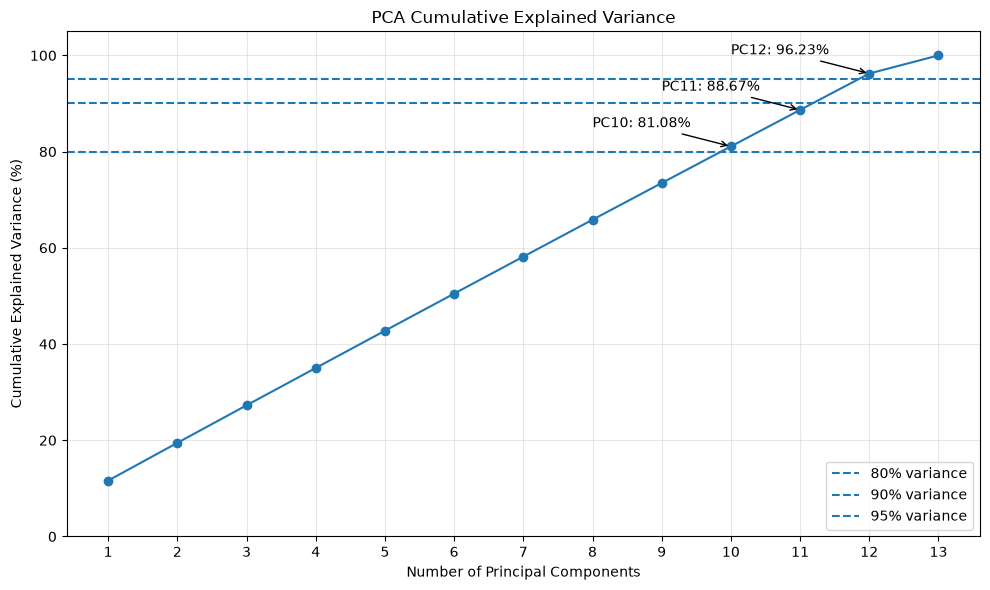

In [10]:
# ------------------------------------------------------------
# CELL 11: VISUALIZE CUMULATIVE EXPLAINED VARIANCE
# ------------------------------------------------------------
# This graph shows how much total variance is retained as more
# principal components are included.
#
# It allows us to visually identify where the cumulative
# explained variance first crosses the 80%, 90%, and 95%
# retention thresholds.
# ------------------------------------------------------------


# ------------------------------------------------------------
# 1. Create component numbers for the x-axis
# ------------------------------------------------------------

component_numbers = np.arange(
    1,
    len(cumulative_variance) + 1
)


# ------------------------------------------------------------
# 2. Create the plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    component_numbers,
    cumulative_variance * 100,
    marker="o"
)


# ------------------------------------------------------------
# 3. Add horizontal variance-threshold reference lines
# ------------------------------------------------------------

plt.axhline(
    y=80,
    linestyle="--",
    label="80% variance"
)

plt.axhline(
    y=90,
    linestyle="--",
    label="90% variance"
)

plt.axhline(
    y=95,
    linestyle="--",
    label="95% variance"
)


# ------------------------------------------------------------
# 4. Highlight the most important component counts
# ------------------------------------------------------------
# PC10 is the first point above 80%.
# PC11 is still below 90%.
# PC12 is the first point above both 90% and 95%.

important_components = [10, 11, 12]

for component in important_components:
    variance_value = cumulative_variance[component - 1] * 100

    plt.annotate(
        f"PC{component}: {variance_value:.2f}%",
        xy=(component, variance_value),
        xytext=(component - 2.0, variance_value + 4),
        arrowprops={"arrowstyle": "->"}
    )


# ------------------------------------------------------------
# 5. Add titles and axis labels
# ------------------------------------------------------------

plt.title(
    "PCA Cumulative Explained Variance"
)

plt.xlabel(
    "Number of Principal Components"
)

plt.ylabel(
    "Cumulative Explained Variance (%)"
)


# ------------------------------------------------------------
# 6. Make every principal-component number visible
# ------------------------------------------------------------

plt.xticks(component_numbers)

plt.ylim(0, 105)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()

## Interpretation of Cumulative Explained Variance

The cumulative explained-variance curve shows how much of the variance in the 13 standardized numerical/ordinal predictors is retained as additional principal components are included.

The key results are:

- **10 principal components** retain approximately **81.08%** of the total variance and are the first to reach the 80% threshold.
- **11 principal components** retain approximately **88.67%**, which is still below the 90% threshold.
- **12 principal components** retain approximately **96.23%**, making 12 the minimum number required to exceed both the 90% and 95% thresholds.
- All **13 principal components** retain 100% of the variance.

Therefore, retaining at least 95% of the variance reduces the numerical feature space from **13 original features to 12 principal components**.

This is only a small dimensionality reduction. The result shows that the variance in this dataset is distributed across many dimensions rather than being concentrated in only a few principal components.

The explained-variance percentage describes how much variation in the PCA input features is preserved. It does **not** represent prediction accuracy or model performance.

In [11]:
# ------------------------------------------------------------
# CELL 13: LEAKAGE-SAFE PCA DEMONSTRATION USING ONE CV FOLD
# ------------------------------------------------------------
# The PCA analysis above was descriptive and used the complete
# 80,000-row development partition.
#
# During predictive cross-validation, however, StandardScaler
# and PCA must NOT be fitted using the validation fold.
#
# Correct procedure:
#
# TRAINING FOLDS
#       ↓
# fit StandardScaler
#       ↓
# transform training data
#       ↓
# fit PCA
#       ↓
# transform training data
#
# VALIDATION FOLD
#       ↓
# use the SAME fitted scaler
#       ↓
# use the SAME fitted PCA
#
# This prevents validation information from influencing the
# learned preprocessing parameters.
# ------------------------------------------------------------


# ------------------------------------------------------------
# 1. Attach CV-fold assignments to the development records
# ------------------------------------------------------------
# Employee_ID is used only to match records with their frozen
# fold assignment. It is NOT a PCA input feature.

development_with_folds = development_df.merge(
    split_registry[
        ["Employee_ID", "partition", "cv_fold"]
    ],
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 2. Verify that all selected records are development records
# ------------------------------------------------------------

assert (
    development_with_folds["partition"] == "development"
).all(), (
    "Non-development rows were found in the CV demonstration."
)

assert development_with_folds["cv_fold"].notna().all(), (
    "Every development row should have a CV-fold assignment."
)


# ------------------------------------------------------------
# 3. Inspect the available CV folds
# ------------------------------------------------------------

available_folds = sorted(
    development_with_folds["cv_fold"].unique()
)

print("Available development CV folds:", available_folds)

print("\nRows per CV fold:")
print(
    development_with_folds["cv_fold"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 4. Select one fold as the validation fold
# ------------------------------------------------------------
# We use the first available fold only as a demonstration.
# The remaining folds become the training data.

validation_fold = available_folds[0]

train_fold_df = development_with_folds.loc[
    development_with_folds["cv_fold"] != validation_fold
].copy()

valid_fold_df = development_with_folds.loc[
    development_with_folds["cv_fold"] == validation_fold
].copy()


# ------------------------------------------------------------
# 5. Select exactly the same 13 PCA input features
# ------------------------------------------------------------

X_train_fold = train_fold_df[pca_features].copy()
X_valid_fold = valid_fold_df[pca_features].copy()


# ------------------------------------------------------------
# 6. Fit StandardScaler ONLY on the training folds
# ------------------------------------------------------------

fold_scaler = StandardScaler()

X_train_scaled = fold_scaler.fit_transform(
    X_train_fold
)

# IMPORTANT:
# transform() is used on validation data.
# We do NOT call fit() or fit_transform() on the validation fold.

X_valid_scaled = fold_scaler.transform(
    X_valid_fold
)


# ------------------------------------------------------------
# 7. Fit PCA ONLY on the scaled training folds
# ------------------------------------------------------------
# n_components=0.95 asks PCA to retain the minimum number of
# components needed to explain at least 95% of the variance
# learned from the TRAINING data only.

fold_pca = PCA(
    n_components=0.95
)

X_train_pca = fold_pca.fit_transform(
    X_train_scaled
)

# Again, validation data is transformed only.
# PCA is NOT refitted using the validation fold.

X_valid_pca = fold_pca.transform(
    X_valid_scaled
)


# ------------------------------------------------------------
# 8. Display the result
# ------------------------------------------------------------

print("\nValidation fold selected:", validation_fold)

print(
    "Training rows:",
    f"{len(X_train_fold):,}"
)

print(
    "Validation rows:",
    f"{len(X_valid_fold):,}"
)

print(
    "\nOriginal number of numerical features:",
    X_train_fold.shape[1]
)

print(
    "Principal components retained at >=95% training variance:",
    fold_pca.n_components_
)

print(
    "Training PCA shape:",
    X_train_pca.shape
)

print(
    "Validation PCA shape:",
    X_valid_pca.shape
)


# ------------------------------------------------------------
# 9. Final safety checks
# ------------------------------------------------------------

assert X_train_pca.shape[1] == X_valid_pca.shape[1], (
    "Training and validation PCA outputs must have the same "
    "number of components."
)

assert X_train_fold.shape[1] == 13, (
    "Expected 13 original PCA input features."
)

print("\nLeakage-safe fold demonstration passed.")
print(
    "Scaler and PCA were fitted on training folds only; "
    "the validation fold was transformed using already-fitted objects."
)

Available development CV folds: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]

Rows per CV fold:
cv_fold
1.0    16000
2.0    16000
3.0    16000
4.0    16000
5.0    16000
Name: count, dtype: int64

Validation fold selected: 1.0
Training rows: 64,000
Validation rows: 16,000

Original number of numerical features: 13
Principal components retained at >=95% training variance: 12
Training PCA shape: (64000, 12)
Validation PCA shape: (16000, 12)

Leakage-safe fold demonstration passed.
Scaler and PCA were fitted on training folds only; the validation fold was transformed using already-fitted objects.


## Final Conclusion

This notebook demonstrated Principal Component Analysis (PCA) as a dimensionality-reduction technique using the project's frozen development partition.

### Main findings

- PCA was applied to exactly **13 approved numerical/ordinal predictors**.
- The target variable `Resigned` was **not used** to construct the principal components.
- The four categorical predictors were excluded from this PCA analysis.
- The numerical features were standardized before PCA because PCA is sensitive to feature scale.
- **10 principal components** retained approximately **81.08%** of the variance.
- **11 principal components** retained approximately **88.67%** of the variance.
- **12 principal components** retained approximately **96.23%** of the variance.
- Therefore, the minimum number of components required for:
  - at least **80%** variance is **10 PCs**;
  - at least **90%** variance is **12 PCs**;
  - at least **95%** variance is **12 PCs**.

At the 95% variance-retention threshold, PCA reduces the numerical feature space from **13 original features to 12 principal components**. Therefore, the dimensionality reduction is limited rather than substantial.

### Leakage prevention

For descriptive analysis, PCA was examined using only the **80,000-row development partition**, while the **20,000-row formal holdout remained excluded from preprocessing decisions**.

For predictive cross-validation, `StandardScaler` and PCA must be fitted only on the active training folds. The validation fold is transformed using the already-fitted scaler and PCA objects. This prevents validation information from influencing the learned preprocessing transformation.

### Final interpretation

PCA creates new weighted combinations of the original standardized numerical features; it does not select the original predictors themselves.

The PCA results are used as a **dimensionality-reduction analysis and benchmark**. They do not imply that PCA must be applied to every later machine-learning model, and explained variance should not be interpreted as predictive accuracy.

In [12]:
# ------------------------------------------------------------
# CELL 15: FINAL PCA NOTEBOOK VERIFICATION
# ------------------------------------------------------------
# This cell checks the main factual and technical claims made
# throughout the notebook.
#
# It is not a modelling step.
# It is a final consistency check so that the notebook ends with
# explicit evidence that the PCA analysis is internally coherent.
# ------------------------------------------------------------


# ------------------------------------------------------------
# 1. Verify the development partition size
# ------------------------------------------------------------

assert len(development_df) == 80_000, (
    f"Expected 80,000 development rows, found {len(development_df):,}."
)


# ------------------------------------------------------------
# 2. Verify the exact PCA input feature count
# ------------------------------------------------------------

assert len(pca_features) == 13, (
    f"Expected 13 PCA input features, found {len(pca_features)}."
)

assert X_pca.shape == (80_000, 13), (
    f"Unexpected PCA input shape: {X_pca.shape}"
)


# ------------------------------------------------------------
# 3. Verify that the target is excluded
# ------------------------------------------------------------

assert "Resigned" not in pca_features, (
    "Target leakage detected: Resigned must not be a PCA input."
)


# ------------------------------------------------------------
# 4. Verify that all PCA inputs are numerical
# ------------------------------------------------------------

assert X_pca.select_dtypes(exclude=np.number).empty, (
    "All PCA input features must be numerical."
)


# ------------------------------------------------------------
# 5. Verify standardization
# ------------------------------------------------------------

assert np.allclose(
    X_scaled_df.mean().to_numpy(),
    0.0,
    atol=1e-10
), (
    "Scaled feature means are not approximately zero."
)

assert np.allclose(
    X_scaled_df.std(ddof=0).to_numpy(),
    1.0,
    atol=1e-10
), (
    "Scaled feature standard deviations are not approximately one."
)


# ------------------------------------------------------------
# 6. Verify full PCA output
# ------------------------------------------------------------

assert X_pca_df.shape == (80_000, 13), (
    f"Unexpected full PCA output shape: {X_pca_df.shape}"
)

assert np.isclose(
    cumulative_variance[-1],
    1.0
), (
    "All 13 principal components should explain approximately 100% "
    "of the input variance."
)


# ------------------------------------------------------------
# 7. Verify the key cumulative-variance results
# ------------------------------------------------------------

assert np.isclose(
    cumulative_variance[9] * 100,
    81.0774,
    atol=0.001
), (
    "PC10 cumulative explained variance does not match the verified result."
)

assert np.isclose(
    cumulative_variance[10] * 100,
    88.6695,
    atol=0.001
), (
    "PC11 cumulative explained variance does not match the verified result."
)

assert np.isclose(
    cumulative_variance[11] * 100,
    96.2309,
    atol=0.001
), (
    "PC12 cumulative explained variance does not match the verified result."
)


# ------------------------------------------------------------
# 8. Verify threshold component counts
# ------------------------------------------------------------

assert components_80 == 10, (
    "Expected 10 principal components for the 80% threshold."
)

assert components_90 == 12, (
    "Expected 12 principal components for the 90% threshold."
)

assert components_95 == 12, (
    "Expected 12 principal components for the 95% threshold."
)


# ------------------------------------------------------------
# 9. Verify the cross-validation split structure
# ------------------------------------------------------------

assert len(available_folds) == 5, (
    f"Expected 5 development folds, found {len(available_folds)}."
)

fold_counts = (
    development_with_folds["cv_fold"]
    .value_counts()
    .sort_index()
)

assert (fold_counts == 16_000).all(), (
    "Expected each development CV fold to contain 16,000 rows."
)

assert len(X_train_fold) == 64_000, (
    f"Expected 64,000 training rows, found {len(X_train_fold):,}."
)

assert len(X_valid_fold) == 16_000, (
    f"Expected 16,000 validation rows, found {len(X_valid_fold):,}."
)


# ------------------------------------------------------------
# 10. Verify leakage-safe PCA demonstration
# ------------------------------------------------------------

assert X_train_pca.shape[1] == X_valid_pca.shape[1], (
    "Training and validation PCA outputs must use the same "
    "number of learned components."
)

assert fold_pca.n_components_ == 12, (
    f"Expected 12 PCs in the >=95% fold-local PCA demonstration, "
    f"found {fold_pca.n_components_}."
)


# ------------------------------------------------------------
# 11. Final report
# ------------------------------------------------------------

print("FINAL PCA NOTEBOOK VERIFICATION")
print("-" * 40)

print("Development rows verified: 80,000")
print("Formal holdout rows used for PCA decisions: 0")

print("\nPCA inputs verified:")
print("- 13 numerical/ordinal predictors")
print("- Resigned excluded")
print("- categorical predictors excluded from this PCA analysis")

print("\nStandardization verified:")
print("- feature means approximately 0")
print("- feature standard deviations approximately 1")

print("\nExplained variance verified:")
print(f"- 10 PCs -> {cumulative_variance[9] * 100:.2f}%")
print(f"- 11 PCs -> {cumulative_variance[10] * 100:.2f}%")
print(f"- 12 PCs -> {cumulative_variance[11] * 100:.2f}%")

print("\nVariance thresholds verified:")
print(f"- >=80% -> {components_80} PCs")
print(f"- >=90% -> {components_90} PCs")
print(f"- >=95% -> {components_95} PCs")

print("\nCross-validation demonstration verified:")
print("- 5 folds")
print("- 16,000 rows per fold")
print("- scaler fitted on training folds only")
print("- PCA fitted on training folds only")
print("- validation fold transformed only")

print("\nAll final PCA notebook checks passed.")

FINAL PCA NOTEBOOK VERIFICATION
----------------------------------------
Development rows verified: 80,000
Formal holdout rows used for PCA decisions: 0

PCA inputs verified:
- 13 numerical/ordinal predictors
- Resigned excluded
- categorical predictors excluded from this PCA analysis

Standardization verified:
- feature means approximately 0
- feature standard deviations approximately 1

Explained variance verified:
- 10 PCs -> 81.08%
- 11 PCs -> 88.67%
- 12 PCs -> 96.23%

Variance thresholds verified:
- >=80% -> 10 PCs
- >=90% -> 12 PCs
- >=95% -> 12 PCs

Cross-validation demonstration verified:
- 5 folds
- 16,000 rows per fold
- scaler fitted on training folds only
- PCA fitted on training folds only
- validation fold transformed only

All final PCA notebook checks passed.
